## NASTRAN SOL 145 FLUTTER ANALYSIS AUTOMATION EXAMPLE

This notebook demonstrates the automation of NASTRAN for SOL 145 flutter analysis at Streamline Aerospace.\
<u>Prerequisites</u>
- Siemens FEMAP: v11.0.1
- NASTRAN Version: V8.5
- Python Version: 3.12.X

In [1]:
#Import Statements
from flutter_nastran import (
    split_nastran_deck,
    flutter_card,
    generate_sol145_master_bdf,
    run_nastran,
    extract_vf_vg_data,
    repair_vf_vg_curves,
    make_vf_vg_plot,
    select_directory,
    find_bdf_files,
    get_subdirectories,
    get_flutter_onset,)
import numpy as np
import warnings
from pathlib import Path
import subprocess
import os

### Inputs
Run the following cell to declare all inputs. Adjust any as needed.

In [2]:
nastran_path = Path(r"C:\FEMAPv1101\nastran\bin\nastran.exe")

#post process setting
damping_threshold = 0.03

#declare flutter sweep parameters 
altitude_ft = 15000 #altitude to survey flutter over 
Mach_min = 0.025
Mach_max = 0.8
Mach_num_pts = 32
spc_id = 3 #! make sure this is set (can actually be read off of input .bdf file)
ref_chord_in = 55
flutter_freq_interval = [0.002, 50] #interval to calculate reduced frequencies from
flutter_freq_max = 40 #maximum frequency for NASTRAN SOL 145 to survey up to 

### Generating Bulk Data Files

Before running this notebook, ensure you have created an adequate structural and aerodynamic analysis model in FEMAP. Once completed, export this analysis model to a .bdf file using File>Export>Analysis Model. Once you've done this, update the filepath field in the code cell below to point to the .bdf file. Of note: Make sure the correct constraint set is referenced in the output analysis set.

In [ ]:
#FEMAP export bdf model (Must contain femap-exported *.bdf files)
working_dir = select_directory(prompt_title="Select Local Working Directory")

os.chdir(working_dir)

analysis_model_bdfs = find_bdf_files(directory=working_dir)
print(f"Found {len(analysis_model_bdfs)} BDF files: {analysis_model_bdfs}")

#check if this working directory contains any subfolders 
subdirs = get_subdirectories(directory=working_dir)
if len(subdirs)>0:
    warnings.warn("Working Directory contains Subdirectories. Continuing may overwrite them")

In [ ]:
folder_paths = [] #store a list of paths to each sub-folder

for model_bdf in analysis_model_bdfs:

    #get analysis model bdf base name
    base_name = model_bdf.name.split(".")[0] #remove file extension

    #create a folder inside the working directory
    folder_path = working_dir + "/" + base_name + f"_{int(altitude_ft/1000)}kft"
    os.makedirs(folder_path, exist_ok=True)
    folder_paths.append(folder_path)

    #generate *_STRUCT.bdf and *_AERO.bdf files 
    struc_path, aero_path = split_nastran_deck(input_bdf_path=model_bdf.name, output_dir=folder_path)

    #generate flutter cards 
    flutter_path = flutter_card(altitude_ft=altitude_ft,
                    Mach_sweep=np.linspace(Mach_min, Mach_max, Mach_num_pts), 
                    freq_interval_Hz=flutter_freq_interval,
                    reference_chord_in=ref_chord_in,
                    output_dir=folder_path)

    #generate master run cards 
    run_file = generate_sol145_master_bdf(flutter_card_path=flutter_path,
                        struct_card_path=struc_path,
                        aero_card_path=aero_path,
                        base_title="RV10_WING",
                        output_dir=folder_path,
                        spc_id=spc_id,
                        max_freq_Hz=flutter_freq_max)

### Running NASTRAN

Now that the suitable .bdf files have been generated. The NASTRAN executable can be called.

In [ ]:
for path in folder_paths: 

    #SEARCH FOR A FILE BEGINNING WITH xRUN
    search_path = Path(path)
    matching_files = list(search_path.glob("xRUN*.bdf"))
    try: 
        assert len(matching_files) == 1 
    except: 
        print("Unable to locate xRUN*.bdf File. Continuing")
        continue 

    input_bdf = matching_files[0]._str

    #attempt to run NASTRAN
    try:
        res = run_nastran(bdf_path=input_bdf,
                            nastran_path=nastran_path)
        print("NASTRAN execution completed successfully.")
        print("STDOUT:\n", res.stdout)
    except subprocess.CalledProcessError as err:
        print(f"NASTRAN run failed with return code {err.returncode}")
        print("STDERR:\n", err.stderr)
        print("STDOUT:\n", err.stdout)

### Postprocessing
Vf-Vg diagrams can be plotted using results found the in the generated .f06 files. The following cell creates matplotlib Vf-Vg plots for all .f06 files where results exist.

findfont: Failed to find font weight normal for Saira, now using 100.
findfont: Failed to find font weight normal for Saira, now using 100.
findfont: Failed to find font weight normal for Saira, now using 100.
findfont: Failed to find font weight bold for Saira, now using 100.
findfont: Failed to find font weight bold for Saira, now using 100.
findfont: Failed to find font weight normal for Saira, now using 100.


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_00GAL_AILFIX\xrun_RV10Wing_00GAL_AILFIX_flutter_15kft.f06


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_00GAL_AILFREE\xrun_RV10Wing_00GAL_AILFREE_flutter_15kft.f06


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_30GAL_AILFIX\xrun_RV10Wing_30GAL_AILFIX_flutter_15kft.f06


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_30GAL_AILFREE\xrun_RV10Wing_30GAL_AILFREE_flutter_15kft.f06


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_41_5GAL_STIFFENED_AILFIX\xrun_41_5GAL_AILFIX_flutter_15kft.f06


Failed to save figure to G:\.shortcut-targets-by-id\1TLkPxhF_a9qKF0esNe9-_JXIEcPOBfxL\00 Streamline\02_Clients\SkyDesigns\01 Tasks\20261021 Flutter Sweep\20261106 RV10 Flutter Plunge Sweep\20261106_RV10Wing_41_5GAL_STIFFENED_AILFREE\xrun_41_5GAL_AILFREE_flutter_15kft.f06
Unstable flutter onset detected at: Mach = [np.float64(0.560228826914123), np.float64(0.23166336870677956), np.float64(0.3921186091874332), np.float64(0.22954257341899953), np.float64(0.2766962802949176), np.float64(0.22046277476634019)]


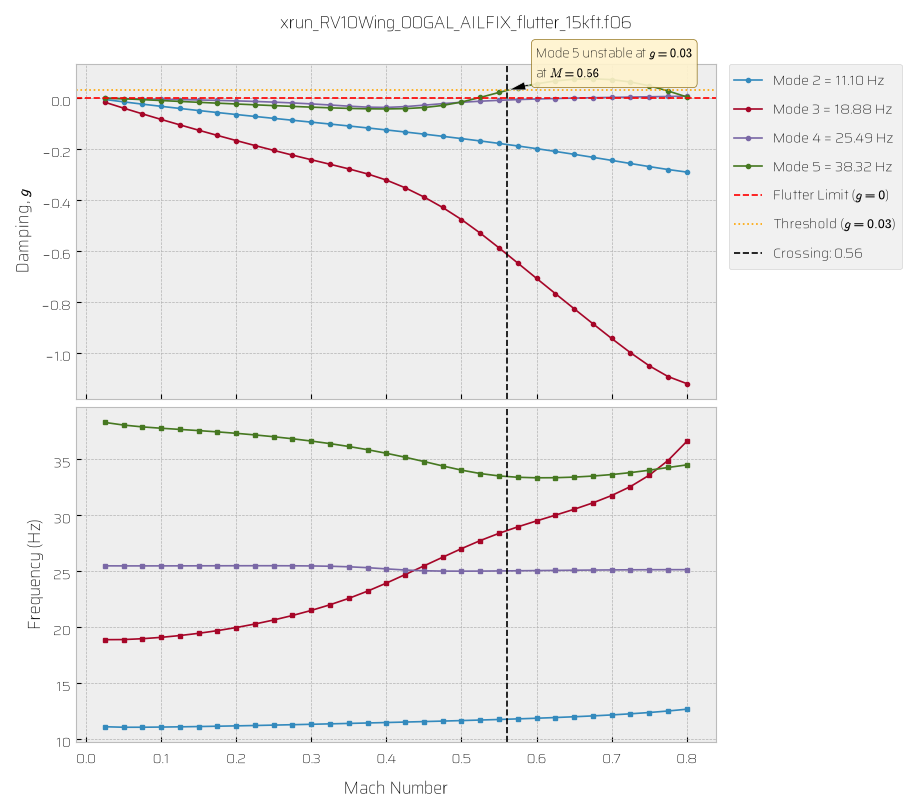

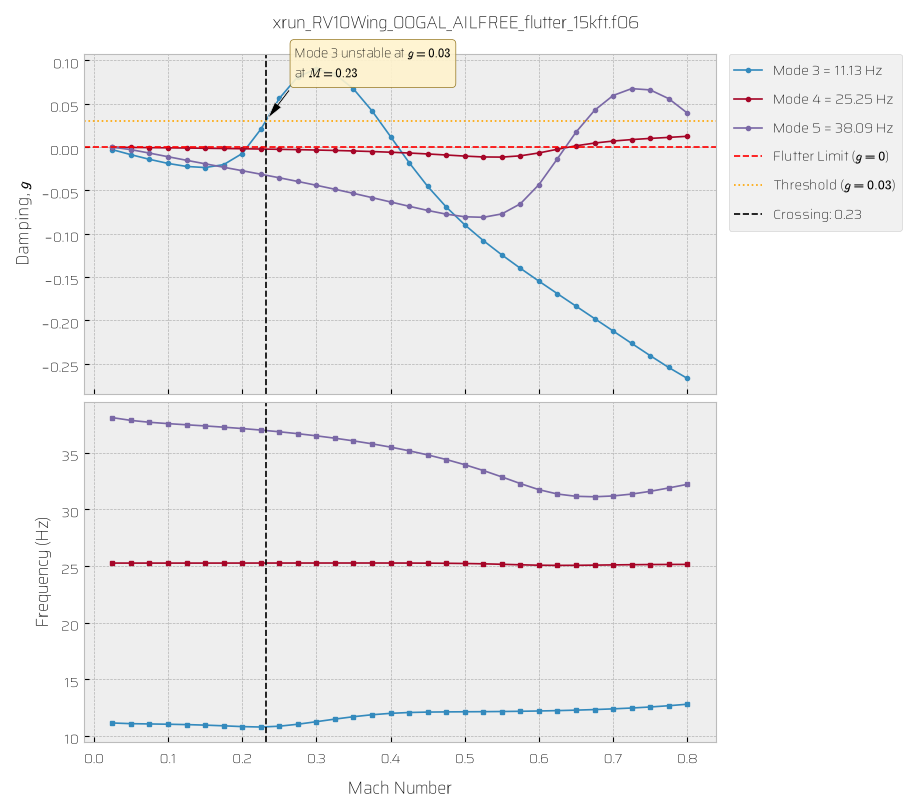

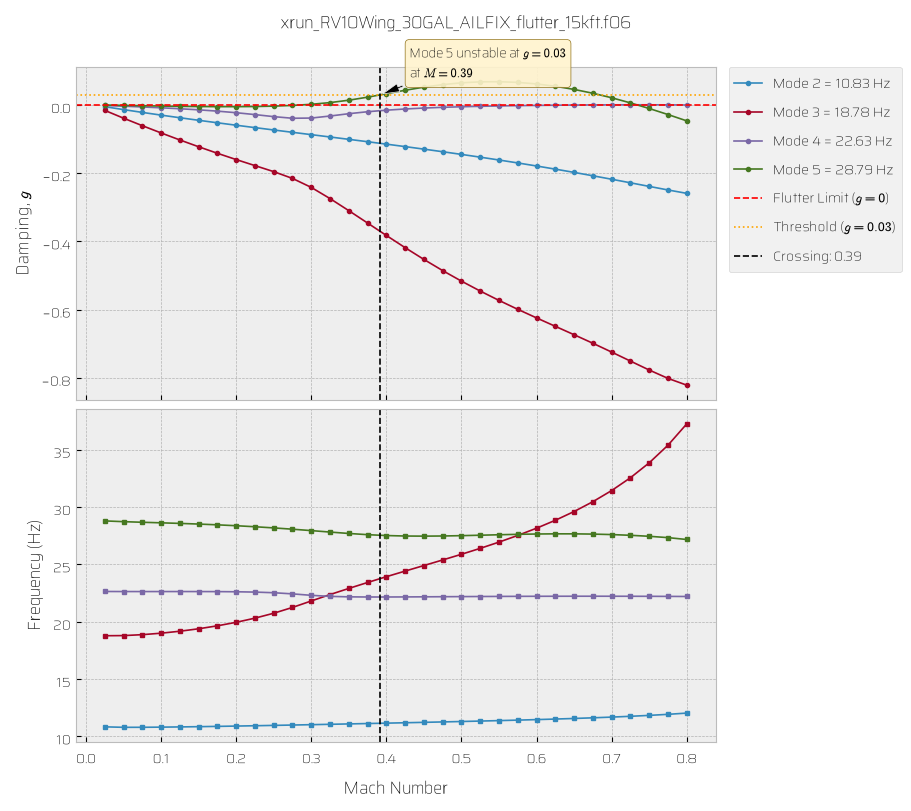

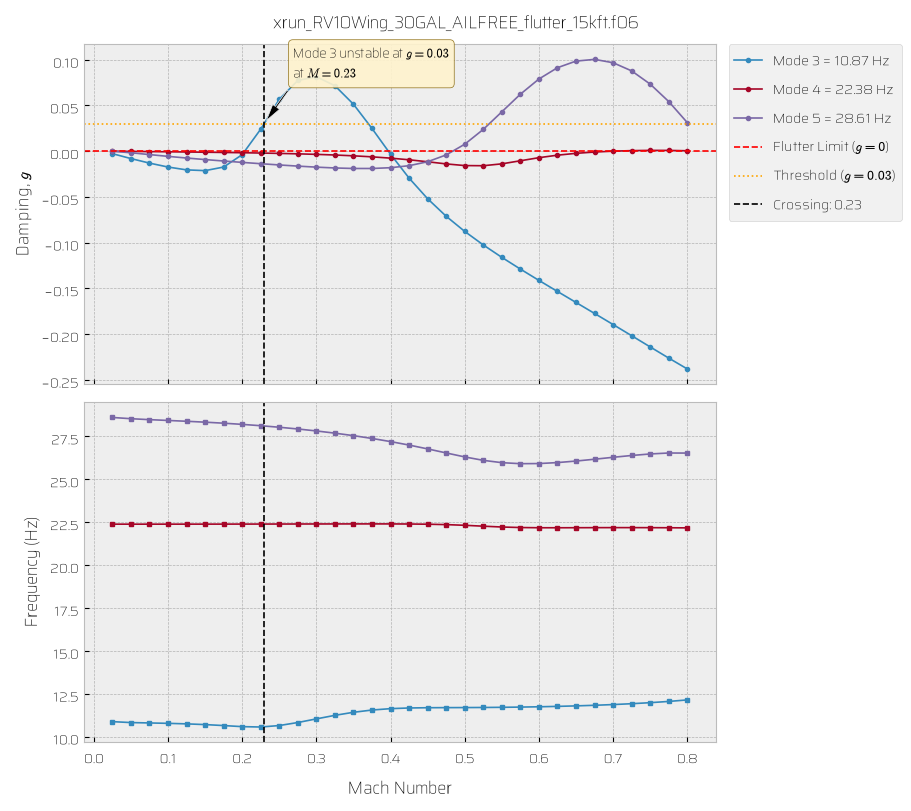

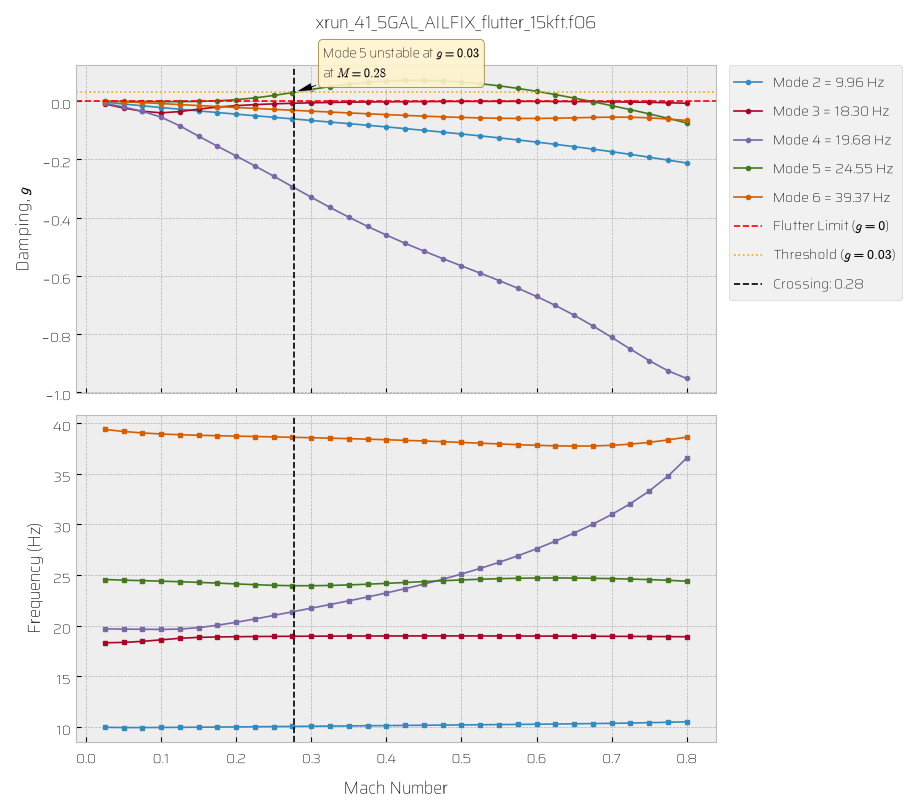

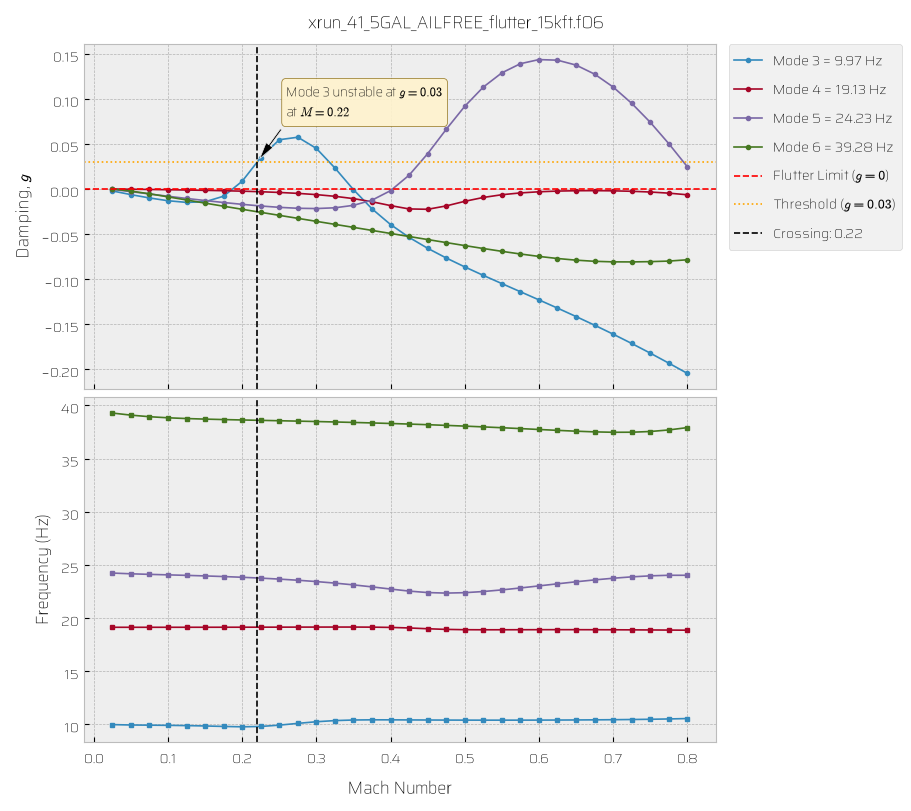

In [3]:
working_dir = select_directory(prompt_title="Select Top-Level Directory Containing .f06 File")
matching_files = list(Path(working_dir).rglob("*.f06"))
Mach_numbers = [] #mach numbers where onset of flutter is expected. Obtained from Vf-Vg diagrams

for filepath in matching_files: 

    #check if file is a single-point complex results set
    if "complex" in filepath.name.lower(): continue 

    #process data in .f06 file 
    raw_data = extract_vf_vg_data(filepath)
    crossings = get_flutter_onset(vf_vg_data=raw_data, damping_threshold=damping_threshold)
    crossings.sort(key=lambda x: x["v_cross"])
    try: 
        Mach_numbers.append(crossings[0]["v_cross"])
    except: Mach_numbers.append(None)

    #fix errors in vf-vg curves due to mode crossings 
    clean_data = repair_vf_vg_curves(raw_data)
    
    # Plots structural modes
    make_vf_vg_plot(
        clean_data,
        suptitle=filepath.name,
        mode_floor_Hz=1,
        damping_threshold=damping_threshold,
        figure_savepath=filepath)

print(f"Unstable flutter onset detected at: Mach = {Mach_numbers}")

## Step 4 - Complex Mode Shape Output

Once you have determined if flutter is present within the Mach envelopes surveyed above, NASTRAN can be used to generate a complex mode shape output. In the Mach_numbers list, enter the mach numbers where the onset of unstable flutter it first observed. This should be at a damping threshold of +0.01 to +0.03 for most aircraft structures.

In [ ]:
#FEMAP export bdf model (Must contain aero and structural model)
working_dir = select_directory(prompt_title="Select BDF Directory")
os.chdir(working_dir)
analysis_model_bdfs = find_bdf_files(directory=working_dir)

#make sure Mach_numbers list is the correct length
assert len(Mach_numbers) == len(analysis_model_bdfs)
complex_folder_paths = []

for i,model_bdf in enumerate(analysis_model_bdfs):

    #get analysis model bdf base name
    base_name = model_bdf.name.split(".")[0] #remove file extension

    #create a folder inside the working directory
    folder_path = working_dir + "/" + base_name + "_COMPLEX"
    os.makedirs(folder_path, exist_ok=True)
    complex_folder_paths.append(folder_path)

    struc_path, aero_path = split_nastran_deck(input_bdf_path=model_bdf.name, output_dir=folder_path)

    flutter_path = flutter_card(altitude_ft=altitude_ft,
                    Mach_sweep=np.array([Mach_numbers[i]]), 
                    freq_interval_Hz=flutter_freq_interval,
                    reference_chord_in=ref_chord_in,
                    output_dir=folder_path,
                    complex_mode_output=True)

    run_file = generate_sol145_master_bdf(flutter_card_path=flutter_path,
                        struct_card_path=struc_path,
                        aero_card_path=aero_path,
                        base_title="RV10_WING",
                        output_dir=folder_path,
                        spc_id=spc_id,
                        max_freq_Hz=flutter_freq_max,
                        complex_mode_output=True)

In [ ]:
for path in complex_folder_paths: 

    #SEARCH FOR A FILE BEGINNING WITH xRUN
    search_path = Path(path)
    matching_files = list(search_path.glob("xRUN*.bdf"))
    try: 
        assert len(matching_files) == 1 
    except: 
        print("Unable to locate xRUN*.bdf File. Continuing")
        continue 

    input_bdf = matching_files[0]._str

    try:
        res = run_nastran(bdf_path=input_bdf,
                            nastran_path=nastran_path)
        print("NASTRAN execution completed successfully.")
        print("STDOUT:\n", res.stdout)
    except subprocess.CalledProcessError as err:
        print(f"NASTRAN run failed with return code {err.returncode}")
        print("STDERR:\n", err.stderr)
        print("STDOUT:\n", err.stdout)

Now that NASTRAN has run succesfully, reimport the solution .op2 file back into FEMAP using file>import>analysis results. This should import multiple mode results sets. Model>Output>Expand Complex on the offending mode to generate multiple phase angle output results sets. Highlight all, right-click, and click animate multiset. A .gif file can now be saved showing the behavior of the structure at the onset of unstable flutter. 